In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [4]:
df = pd.read_csv('/content/CAR DETAILS FROM CAR DEKHO.csv')

# Remove exact duplicates
df = df.drop_duplicates()

print("Dataset shape:", df.shape)

Dataset shape: (3577, 8)


In [5]:
# Extract brand from car name
df['brand'] = df['name'].str.split().str[0]

# Clean brand names
df['brand'] = df['brand'].replace({
    'Land': 'Land Rover',
    'OpelCorsa': 'Opel'
})

# Create car age using the dataset's reference year (2020)
df['car_age'] = 2020 - df['year']

print(df[['name', 'brand', 'year', 'car_age']].head())

                       name    brand  year  car_age
0             Maruti 800 AC   Maruti  2007       13
1  Maruti Wagon R LXI Minor   Maruti  2007       13
2      Hyundai Verna 1.6 SX  Hyundai  2012        8
3    Datsun RediGO T Option   Datsun  2017        3
4     Honda Amaze VX i-DTEC    Honda  2014        6


In [6]:
# Define input features and target
features = [
    'car_age',
    'km_driven',
    'fuel',
    'seller_type',
    'transmission',
    'owner',
    'brand'
]

target = 'selling_price'

X = df[features]
y = df[target]

print("Features:")
print(X.columns.tolist())

print("\nTarget:", y.name)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['car_age', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'brand']

Target: selling_price

X shape: (3577, 7)
y shape: (3577,)


In [7]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2861, 7)
Testing features: (716, 7)

Training target: (2861,)
Testing target: (716,)


In [8]:
# Define numerical and categorical features
numerical_features = [
    'car_age',
    'km_driven'
]

categorical_features = [
    'fuel',
    'seller_type',
    'transmission',
    'owner',
    'brand'
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['car_age', 'km_driven']

Categorical features:
['fuel', 'seller_type', 'transmission', 'owner', 'brand']


In [9]:
# Preprocessing for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [10]:
# Create Linear Regression pipeline
linear_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]
)

print("Linear Regression pipeline created successfully.")

Linear Regression pipeline created successfully.


In [11]:
# Train Linear Regression model
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [12]:
# Generate predictions on unseen test data
y_pred_linear = linear_model.predict(X_test)

print("First 10 actual prices:")
print(y_test.head(10).values)

print("\nFirst 10 predicted prices:")
print(y_pred_linear[:10])

First 10 actual prices:
[ 270000  525000  990000 3800000  229999  325000  210000  500000  790000
  360000]

First 10 predicted prices:
[ 527598.68389147  470511.05874221  954226.81956866 2035912.173455
  142907.0374495   376685.85430475  168012.20839455  530739.96350661
  801827.08106005  418051.93210118]


In [13]:
# Evaluate Linear Regression
mae_linear = mean_absolute_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("--------------------------------")
print(f"MAE  : ₹{mae_linear:,.2f}")
print(f"RMSE : ₹{rmse_linear:,.2f}")
print(f"R²   : {r2_linear:.4f}")

Linear Regression Performance
--------------------------------
MAE  : ₹179,642.88
RMSE : ₹384,722.37
R²   : 0.5405


In [14]:
# Create Decision Tree Regression pipeline
tree_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', DecisionTreeRegressor(
            random_state=42
        ))
    ]
)

print("Decision Tree pipeline created successfully.")

Decision Tree pipeline created successfully.


In [15]:
# Train Decision Tree
tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [16]:
# Generate predictions using Decision Tree
y_pred_tree = tree_model.predict(X_test)

print("First 10 actual prices:")
print(y_test.head(10).values)

print("\nFirst 10 Decision Tree predictions:")
print(y_pred_tree[:10])

First 10 actual prices:
[ 270000  525000  990000 3800000  229999  325000  210000  500000  790000
  360000]

First 10 Decision Tree predictions:
[ 584000.  550000. 1800000. 2000000.  350000.  385000.  220000.  650000.
  844999.  500000.]


In [17]:
# Evaluate Decision Tree
mae_tree = mean_absolute_error(y_test, y_pred_tree)

rmse_tree = np.sqrt(
    mean_squared_error(y_test, y_pred_tree)
)

r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Performance")
print("--------------------------------")
print(f"MAE  : ₹{mae_tree:,.2f}")
print(f"RMSE : ₹{rmse_tree:,.2f}")
print(f"R²   : {r2_tree:.4f}")

Decision Tree Performance
--------------------------------
MAE  : ₹195,085.31
RMSE : ₹471,391.30
R²   : 0.3102


In [18]:
# Create Random Forest Regression pipeline
random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [19]:
# Train Random Forest
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [20]:
# Generate predictions using Random Forest
y_pred_rf = random_forest_model.predict(X_test)

print("First 10 actual prices:")
print(y_test.head(10).values)

print("\nFirst 10 Random Forest predictions:")
print(y_pred_rf[:10])

First 10 actual prices:
[ 270000  525000  990000 3800000  229999  325000  210000  500000  790000
  360000]

First 10 Random Forest predictions:
[ 578831.64772727  472577.91516667 1474134.8965     2549629.15166667
  247944.995       348888.4925      183725.          665945.93
  889570.0852381   468705.        ]


In [21]:
# Evaluate Random Forest
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------------")
print(f"MAE  : ₹{mae_rf:,.2f}")
print(f"RMSE : ₹{rmse_rf:,.2f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest Performance
--------------------------------
MAE  : ₹157,686.48
RMSE : ₹363,871.46
R²   : 0.5890


compared Linear Regression, Decision Tree Regression, and Random Forest Regression using MAE, RMSE, and R² on the same test set. Random Forest achieved the lowest MAE and RMSE and the highest R² of 0.5890, so I selected it as the final model.

In [22]:
# Create model comparison table
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [
        mae_linear,
        mae_tree,
        mae_rf
    ],
    'RMSE': [
        rmse_linear,
        rmse_tree,
        rmse_rf
    ],
    'R2': [
        r2_linear,
        r2_tree,
        r2_rf
    ]
})

print(model_comparison.round(4))

               Model          MAE         RMSE      R2
0  Linear Regression  179642.8769  384722.3655  0.5405
1      Decision Tree  195085.3119  471391.3014  0.3102
2      Random Forest  157686.4760  363871.4626  0.5890


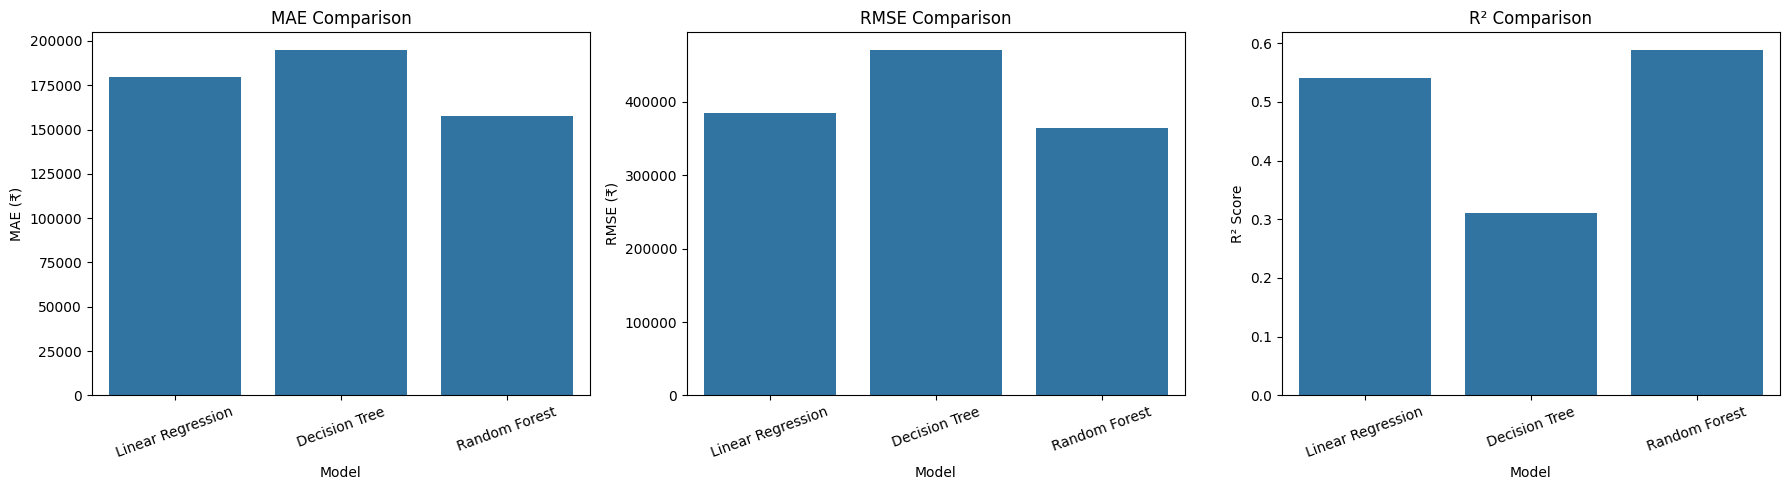

In [23]:
# Model comparison visualization

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# MAE
sns.barplot(data=model_comparison, x='Model', y='MAE', ax=axes[0])
axes[0].set_title('MAE Comparison')
axes[0].set_ylabel('MAE (₹)')
axes[0].tick_params(axis='x', rotation=20)

# RMSE
sns.barplot(data=model_comparison, x='Model', y='RMSE', ax=axes[1])
axes[1].set_title('RMSE Comparison')
axes[1].set_ylabel('RMSE (₹)')
axes[1].tick_params(axis='x', rotation=20)

# R²
sns.barplot(data=model_comparison, x='Model', y='R2', ax=axes[2])
axes[2].set_title('R² Comparison')
axes[2].set_ylabel('R² Score')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

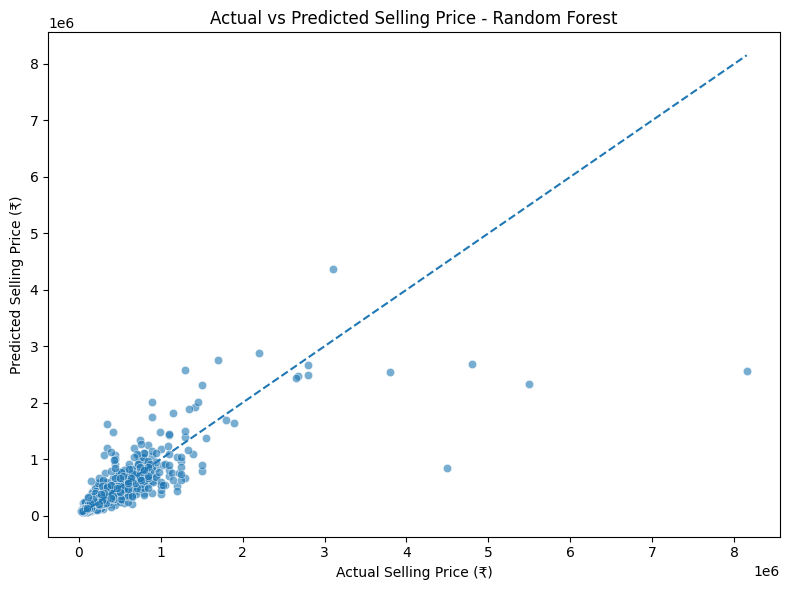

In [24]:
# Actual vs Predicted Prices - Random Forest

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_rf,
    alpha=0.6
)

# Perfect prediction line
min_price = min(y_test.min(), y_pred_rf.min())
max_price = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle='--'
)

plt.xlabel('Actual Selling Price (₹)')
plt.ylabel('Predicted Selling Price (₹)')
plt.title('Actual vs Predicted Selling Price - Random Forest')

plt.tight_layout()
plt.show()

The Actual vs Predicted plot shows that most predictions follow the general trend of actual selling prices, particularly in the lower and middle price ranges. However, the model tends to underpredict some high-priced vehicles, indicating that extreme price values are more difficult to estimate.

In [25]:
# Feature importance from Random Forest

# Get the fitted preprocessor and Random Forest
rf_preprocessor = random_forest_model.named_steps['preprocessor']
rf_regressor = random_forest_model.named_steps['regressor']

# Get feature names after preprocessing
feature_names = rf_preprocessor.get_feature_names_out()

# Get importance values
importances = rf_regressor.feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15
print(feature_importance.head(15))

                        Feature  Importance
0                  num__car_age    0.221724
1                num__km_driven    0.133615
10     cat__transmission_Manual    0.125950
9   cat__transmission_Automatic    0.121628
3              cat__fuel_Diesel    0.071545
17              cat__brand_Audi    0.048445
5              cat__fuel_Petrol    0.044036
29        cat__brand_Land Rover    0.039985
40            cat__brand_Toyota    0.036871
18               cat__brand_BMW    0.014345
6       cat__seller_type_Dealer    0.011385
7   cat__seller_type_Individual    0.011082
33     cat__brand_Mercedes-Benz    0.010541
27            cat__brand_Jaguar    0.010396
32            cat__brand_Maruti    0.010166


In [26]:
# Aggregate feature importance back to the original features

feature_importance['Original_Feature'] = feature_importance['Feature'].apply(
    lambda x: x.split('__')[1].split('_')[0]
    if '__' in x else x
)

# Correctly map encoded features to their original feature names
def get_original_feature(feature):
    feature = feature.replace('num__', '').replace('cat__', '')

    for col in ['car_age', 'km_driven', 'fuel', 'seller_type',
                'transmission', 'owner', 'brand']:
        if feature == col or feature.startswith(col + '_'):
            return col

    return feature

feature_importance['Original_Feature'] = (
    feature_importance['Feature'].apply(get_original_feature)
)

# Aggregate importance
original_feature_importance = (
    feature_importance
    .groupby('Original_Feature')['Importance']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(original_feature_importance)

  Original_Feature  Importance
0     transmission    0.247578
1            brand    0.239958
2          car_age    0.221724
3        km_driven    0.133615
4             fuel    0.115731
5      seller_type    0.023465
6            owner    0.017929


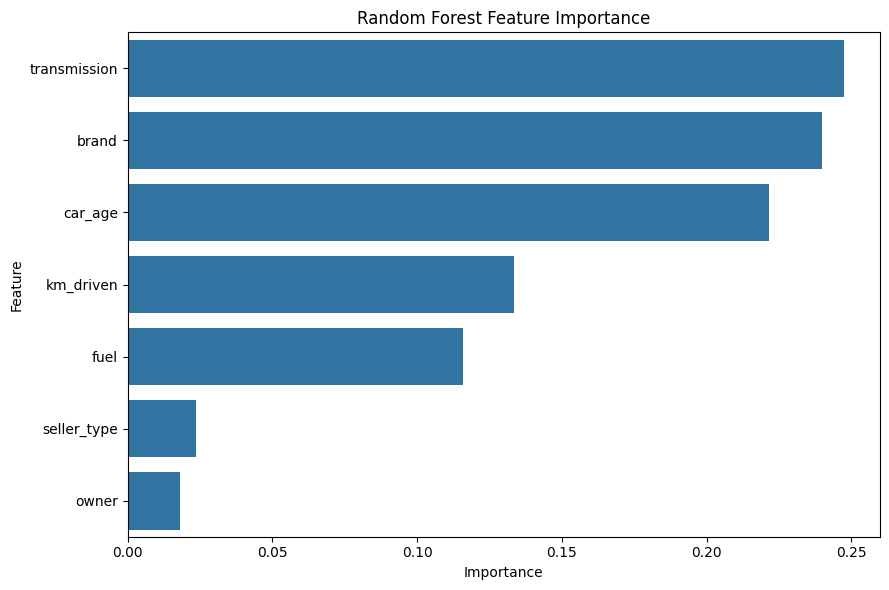

In [27]:
# Feature Importance Visualization

plt.figure(figsize=(9, 6))

sns.barplot(
    data=original_feature_importance,
    x='Importance',
    y='Original_Feature'
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance')

plt.tight_layout()
plt.show()

In [28]:
# Save the final Random Forest pipeline

model_filename = "car_price_random_forest.pkl"

joblib.dump(random_forest_model, model_filename)

print(f"Model saved successfully as: {model_filename}")

Model saved successfully as: car_price_random_forest.pkl


In [29]:
import os

print("File exists:", os.path.exists(model_filename))

if os.path.exists(model_filename):
    print("File size:", os.path.getsize(model_filename), "bytes")

File exists: True
File size: 46071914 bytes


In [30]:
from google.colab import files

files.download("car_price_random_forest.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
# Test loading the saved model

loaded_model = joblib.load("car_price_random_forest.pkl")

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [32]:
# Test prediction using the saved model

test_car = pd.DataFrame({
    'car_age': [5],
    'km_driven': [50000],
    'fuel': ['Petrol'],
    'seller_type': ['Individual'],
    'transmission': ['Manual'],
    'owner': ['First Owner'],
    'brand': ['Maruti']
})

predicted_price = loaded_model.predict(test_car)[0]

print(f"Predicted Selling Price: ₹{predicted_price:,.2f}")

Predicted Selling Price: ₹260,721.21


In [33]:
import json
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,
    "Random Forest": random_forest_model,
}

results = []
for name, mdl in models.items():
    p_tr = mdl.predict(X_train)
    p_te = mdl.predict(X_test)
    results.append({
        "Model": name,
        "Train_MAE": round(float(mean_absolute_error(y_train, p_tr)), 2),
        "Test_MAE": round(float(mean_absolute_error(y_test, p_te)), 2),
        "Test_RMSE": round(float(np.sqrt(mean_squared_error(y_test, p_te))), 2),
        "Train_R2": round(float(r2_score(y_train, p_tr)), 4),
        "Test_R2": round(float(r2_score(y_test, p_te)), 4),
    })

importance = {r.Original_Feature: round(float(r.Importance), 4)
              for r in original_feature_importance.itertuples()}

out = {"models": results, "rf_feature_importance": importance}
print(json.dumps(out, indent=2))

with open("metrics.json", "w") as f:
    json.dump(out, f, indent=2)

from google.colab import files
files.download("metrics.json")

{
  "models": [
    {
      "Model": "Linear Regression",
      "Train_MAE": 162856.49,
      "Test_MAE": 179642.88,
      "Test_RMSE": 384722.37,
      "Train_R2": 0.6608,
      "Test_R2": 0.5405
    },
    {
      "Model": "Decision Tree",
      "Train_MAE": 17137.37,
      "Test_MAE": 195085.31,
      "Test_RMSE": 471391.3,
      "Train_R2": 0.9887,
      "Test_R2": 0.3102
    },
    {
      "Model": "Random Forest",
      "Train_MAE": 61687.34,
      "Test_MAE": 157686.48,
      "Test_RMSE": 363871.46,
      "Train_R2": 0.9432,
      "Test_R2": 0.589
    }
  ],
  "rf_feature_importance": {
    "transmission": 0.2476,
    "brand": 0.24,
    "car_age": 0.2217,
    "km_driven": 0.1336,
    "fuel": 0.1157,
    "seller_type": 0.0235,
    "owner": 0.0179
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>